# Install Requirements

In [11]:
%pip install -r pip_requirements.txt

  Using cached datasets-2.18.0-py3-none-any.whl.metadata (20 kB)
  Using cached transformers-4.39.3-py3-none-any.whl.metadata (134 kB)
  Using cached sentencepiece-0.2.0.tar.gz (2.6 MB)
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Using cached wandb-0.17.2-py3-none-macosx_10_9_x86_64.whl.metadata (10 kB)
  Using cached jupyter-1.1.1-py2.py3-none-any.whl.metadata (2.0 kB)
  Using cached filelock-3.20.0-py3-none-any.whl.metadata (2.1 kB)
  Using cached pyarrow-22.0.0-cp313-cp313-macosx_12_0_x86_64.whl.metadata (3.2 kB)
  Using cached pyarrow_hotfix-0.7-py3-none-any.whl.metadata (3.6 kB)
  Using cached dill-0.3.8-py3-none-any.whl.metadata (10 kB)
  Using cached tqdm-4.67.1-py3-none-any.whl.metadata (57 kB)
  Using cached xxhash-3.6.0-cp313-cp313-macosx_10_13_x86_64.whl.metadata (13 kB)
  Using cached multiprocess-0.70.18-py313-none-any.whl.metadata (7.2 kB)
  Using cached fsspec-2024.2.0-py3-none-a

# Imports

In [12]:
# Jupyter Notebook Utils
%matplotlib inline
%load_ext autoreload
%autoreload 2

# Python Libraries
import pandas as pd
import numpy as np
from datetime import date
import matplotlib.pyplot as plt
import seaborn as sns
import math
from scipy import stats
from statsmodels.stats import diagnostic
import statsmodels.api as sm
import statsmodels.formula.api as smf

# Own modules
from src import *

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## PROJECT PIPELINE
### **PHASE 1: DATA PREPARATION** (Milestone P2)

### STEP 1: Preprocessing & Cleaning
#### Data Quality Checks, Unification & Standardization

1. Import TSV files and expand PROPERTIES column into 86 features
2. Create unified view with `link_type` column for combined analyses (single merged dataset between title and body)
3. Standardize subreddit names (lowercase, trim whitespace)
4. Convert timestamps to datetime and split into year, month, and day columns. 
5. Format embeddings datasets (one subreddit per row, one column for each embedding dimension)
6. Check data quality (missing values, timestamp parsing)
7. Check for duplicates and document dataset overlap





In [13]:
# Data quality and duplicates check
check_quality(interactions_df)
check_quality(embeddings_subreddits_df)
check_quality(embeddings_users_df)


=== QUALITY REPORT ===
Shape: (858488, 92)

Missing values:
 SOURCE_SUBREDDIT                          0
LIWC_COGMECH                              0
LIWC_PERCEPT                              0
LIWC_EXCL                                 0
LIWC_INCL                                 0
                                         ..
LIWC_PPRON                                0
LIWC_PRONOUN                              0
LIWC_FUNCT                                0
COMPOUND_SENTIMENT_CALCULATED_BY_VADER    0
TYPE                                      0
Length: 92, dtype: int64

Duplicate rows: 0

=== QUALITY REPORT ===
Shape: (51278, 301)

Missing values:
 SUBREDDIT    0
emb_206      0
emb_204      0
emb_203      0
emb_202      0
            ..
emb_99       0
emb_98       0
emb_97       0
emb_96       0
emb_299      0
Length: 301, dtype: int64

Duplicate rows: 0

=== QUALITY REPORT ===
Shape: (118381, 301)

Missing values:
 USER       0
emb_206    0
emb_204    0
emb_203    0
emb_202    0
          

In [14]:
# DataFrame after STEP 1 
interactions_df.head()

,SOURCE_SUBREDDIT,TARGET_SUBREDDIT,POST_ID,TIMESTAMP,LINK_SENTIMENT,NUMBER_OF_CHARACTERS,NUMBER_OF_CHARACTERS_WITHOUT_COUNTING_WHITE_SPACE,FRACTION_OF_ALPHABETICAL_CHARACTERS,FRACTION_OF_DIGITS,FRACTION_OF_UPPERCASE_CHARACTERS,...,LIWC_LEISURE,LIWC_HOME,LIWC_MONEY,LIWC_RELIG,LIWC_DEATH,LIWC_ASSENT,LIWC_DISSENT,LIWC_NONFLU,LIWC_FILLER,TYPE
0,agitation,changemyview,1u5cj7s,2013-12-31 16:20:20,1,102.0,91.0,0.843137,0.000000,0.088235,...,0.000000,0.0,0.0,0.0,0.0000,0.0,0.0,0.000000,0.000000,title
1,rddtgaming,rddtrust,1u4pzzs,2013-12-31 16:39:18,1,25.0,23.0,0.760000,0.000000,0.440000,...,0.000000,0.0,0.0,0.0,0.0000,0.0,0.0,0.000000,0.000000,title
2,leagueoflegends,teamredditteams,1u4nrps,2013-12-31 16:39:58,1,345.0,298.0,0.756522,0.017391,0.086957,...,0.034483,0.0,0.0,0.0,0.0000,0.0,0.0,0.000000,0.000000,body
3,examplesofevil,pics,1u5lhas,2013-12-31 16:40:29,1,96.0,83.0,0.833333,0.000000,0.062500,...,0.000000,0.0,0.0,0.0,0.0625,0.0,0.0,0.000000,0.000000,title
4,nfl,cfb,1u4sjvs,2013-12-31 17:37:55,1,1124.0,949.0,0.772242,0.001779,0.057829,...,0.020833,0.0,0.0,0.0,0.0000,0.0,0.0,0.020833,0.005208,body


### STEP 2: Key Metric Definition

**Aggregation Levels:**
All metrics computed at multiple scopes:
- Subreddit level (aggregated over time windows)
- Subreddit-pair level (source → target relationships)
- Community cluster level (aggregated within detected communities)

#### Toxicity Metric Definitions
Define and compute core toxicity metrics that will be used throughout the analysis:

**Intensity Metrics:**
To capture severity of toxic behavior: 
- `toxicity_intensity`: Weighted score combining LINK_SENTIMENT with linguistic features
  - Formula: `α×LIWC_Anger + β×LIWC_Swear + γ×LIWC_Negemo + δ×Negative_VADER + ε×LINK_SENTIMENT`

# ! CYPRIEN ! --> TO BE MODIFIED SINCE WE CHANGED HOW WE COMPUTE AND USE THE TOXICITY METRIC

- `base_toxicity_offset`: A baseline offset computed by averaging toxicity_intensity scores across all links to establish a reference point. 
This would also be used as a threshold for defining toxic vs non-toxic messages.

- `toxicity_std`: The standard deviation of toxicity_intensity scores across all links.

- `toxicity_zscore = (toxicity_intensity - base_toxicity_offset) / toxicity_std`: this formula would standardise toxicity_intensity scores to allow meaningful comparisons across different links. 



### Provided properties are not enough.

LIWC properties represent the proportion of words in a text that belong to a certain lexicon: $\text{LIWC}_X = \frac{\text{nb words in lexicon } X}{\text{total nb words}}$.

Properties like `LIWC_Anger` or `LIWC_Swear` are thus purely lexical.

The `VADER` score, while being more optimized for social media texts and posts, mainly works like a LIWC score and is practically a lexical repertory of words that are conventionally considered negative or harmful on social platforms.

This cannot be considered an accurate measure of negativity in our study because:

A few examples of caveats thats come with using lexicon-based metrics are: 

- Sarcasm, irony, and context
  - “Stupid guy” in a link targeting a funny video of a guy slipping 
  - “Stupid guy” in a link targeting a video of Trump’s speech  

- Cultural difference in language
  - Some communities are (by culture) founded on “offensive” language without being toxic.
  - For example, a *CallOfDuty* subreddit will frequently mention terms like “grenade” or “headshots.” These words are not toxic in that community, but could be considered so in other subreddits (ones not related to war or gaming).


### Good news: `LINK_SENTIMENT` solves this problem

`LINK_SENTIMENT` is derived using a supervised sentiment classifier trained on manually labeled Reddit data. When labeling, the authors have taken into account their human judgement of context, irony etc. in addition of a purely lexical analysis. So `LINK_SENTIMENT` is designed specifically for inter-subreddit interactions and is our most reliable (categorical) measure for pure negativity.

### But we are interested in toxicity, not just negativity…

Our idea: create a custom toxicity metric that is a weighted average relevant properties (from the 86 provided features).


#### How do we define toxicity?

| Dimension | Description | Example of properties to use |
|------------|--------------|------------------|
| **Emotional intensity** | Measures strength of negative emotion | `Neg_Vader`, `LIWC_Negemo`, `LIWC_Anger`, `LIWC_Anx`... |
| **Aggressive** | Captures hostile or taboo language | `LIWC_Swear`, `LIWC_Sexual`, `LIWC_Death`, `LIWC_Relig`... |
| **Targeting** | Focus on others (potential hostility toward people/groups) | `LIWC_You`, `LIWC_Humans`, `LIWC_Social`... |
| **Not cognitive** | Opposite of reasoned or analytical tone | `LIWC_Insight`, `LIWC_Cause`... |
| **Violent and short** | Style indicators of impulsive or aggressive speech | Number of UPPERCASE words, Readability index, Average word length... |


#### Quantitative check

We want to explore what are the properties that play a determinant role in negativity (which is, as explained above, accurately measured by LINK_SENTIMENT). To do so, we compare the normalized property means between positive and negative links (normalized because some properties have different scales and centers). Look which are the most significantly different for positive VS negative links.


,NUMBER_OF_CHARACTERS,NUMBER_OF_CHARACTERS_WITHOUT_COUNTING_WHITE_SPACE,FRACTION_OF_ALPHABETICAL_CHARACTERS,FRACTION_OF_DIGITS,FRACTION_OF_UPPERCASE_CHARACTERS,FRACTION_OF_WHITE_SPACES,FRACTION_OF_SPECIAL_CHARACTERS_SUCH_AS_COMMA_EXCLAMATION_MARK_ETC,NUMBER_OF_WORDS,NUMBER_OF_UNIQUE_WORDS,NUMBER_OF_LONG_WORDS_AT_LEAST_6_CHARACTERS,...,LIWC_ACHIEV,LIWC_LEISURE,LIWC_HOME,LIWC_MONEY,LIWC_RELIG,LIWC_DEATH,LIWC_ASSENT,LIWC_DISSENT,LIWC_NONFLU,LIWC_FILLER
min,7.0,7.0,0.016340,0.00000,0.000505,0.000126,0.001277,1.0,1.0,0.0,...,0.000000,0.0,0.000000,0.000000,0.00,0.0,0.000000,0.000000,0.0,0.0
median,107.0,94.0,0.777778,0.00000,0.083333,0.146341,0.062554,18.0,17.0,4.0,...,0.000000,0.0,0.000000,0.000000,0.00,0.0,0.000000,0.000000,0.0,0.0
max,41239.0,39369.0,0.994208,0.85077,0.993485,0.880000,0.917808,7600.0,2693.0,1978.0,...,0.555556,0.9,0.555556,0.916667,0.75,0.6,0.769231,0.967742,0.6,0.6


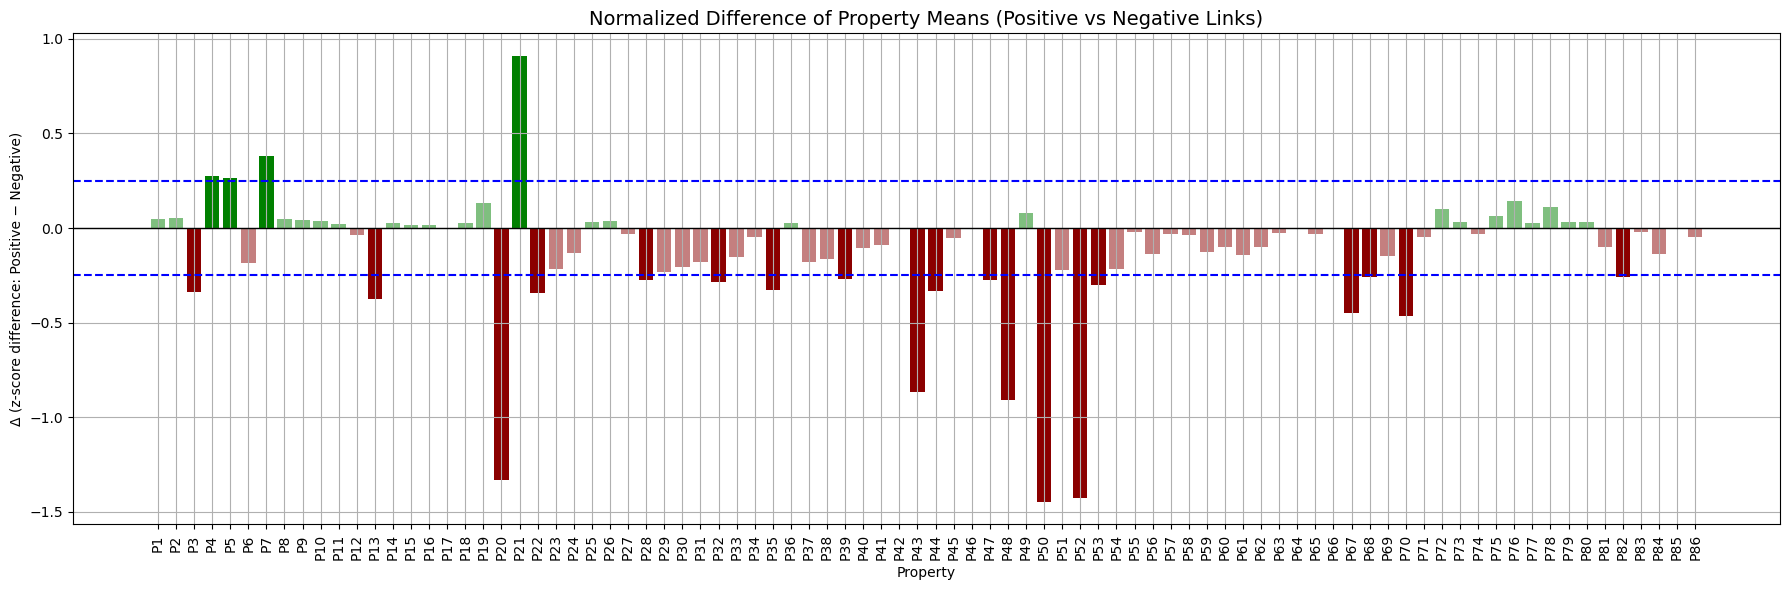

Found 4 properties higher for positive links (zΔ > 0.25):
- (z_diff = 0.273) 	 FRACTION_OF_DIGITS
- (z_diff = 0.262) 	 FRACTION_OF_UPPERCASE_CHARACTERS
- (z_diff = 0.382) 	 FRACTION_OF_SPECIAL_CHARACTERS_SUCH_AS_COMMA_EXCLAMATION_MARK_ETC
- (z_diff = 0.911) 	 COMPOUND_SENTIMENT_CALCULATED_BY_VADER

 Found 19 Properties higher for negative links (zΔ < -0.25):
- (z_diff = -0.34) 	 FRACTION_OF_ALPHABETICAL_CHARACTERS
- (z_diff = -0.375) 	 FRACTION_OF_STOPWORDS
- (z_diff = -1.33) 	 NEGATIVE_SENTIMENT_CALCULATED_BY_VADER
- (z_diff = -0.346) 	 LIWC_FUNCT
- (z_diff = -0.272) 	 LIWC_SHEHE
- (z_diff = -0.287) 	 LIWC_VERBS
- (z_diff = -0.326) 	 LIWC_PRESENT
- (z_diff = -0.27) 	 LIWC_CONJ
- (z_diff = -0.867) 	 LIWC_SWEAR
- (z_diff = -0.33) 	 LIWC_SOCIAL
- (z_diff = -0.273) 	 LIWC_HUMANS
- (z_diff = -0.909) 	 LIWC_AFFECT
- (z_diff = -1.448) 	 LIWC_NEGEMO
- (z_diff = -1.425) 	 LIWC_ANGER
- (z_diff = -0.302) 	 LIWC_SAD
- (z_diff = -0.451) 	 LIWC_BIO
- (z_diff = -0.259) 	 LIWC_BODY
- (z_diff = -0.465

In [16]:
threshold = 0.25
avg_z_diffs = evaluate_props_norm_diffs(interactions_df, threshold)

Combining our qualitative choice of what defines toxicity with the constraint to mainly use properties that prove to appear in negative hyperlinks only, below is our final choice of the toxicity_metric. Note that all these properties represent ratios (values between 0 and 1) that showed to be significantly lower for positive than for negative links.

Our `TOXICITY_SCORE` metric will be a combination of all these properties.

For this initial exploration, we define the continuous `TOXICITY_SCORE` as a **weighted average** of the retained properties. The current weights are derived from intuitive coefficients based on established literature in toxicity and destructive discourse, prioritizing a fast, interpretable metric that reflects our working definition of toxicity. While this approach is simple and effective for preliminary analysis, in the future we plan to explore more advanced options, such as performing Logistic Regression on a small, manually labeled subset of the data to derive statistically optimized weights, for example. It can also turn out better to do more than a simple linear combination and we might use interaction terms and non-linear functions of property scores.

In [17]:
interactions_df["LINK_SENTIMENT_ADJUST"] = (1 - (interactions_df["LINK_SENTIMENT"] + 1)/2)/4

tox_props = pd.DataFrame([
    [-3, "FRACTION_OF_DIGITS"],
    [0, "LINK_SENTIMENT_ADJUST"],
    [1, "FRACTION_OF_STOPWORDS"],
    [5, "NEGATIVE_SENTIMENT_CALCULATED_BY_VADER"],
    [-5, "LIWC_CAUSE"],
    [-5, "LIWC_INSIGHT"],
    [5, "LIWC_SWEAR"],
    [1, "LIWC_SOCIAL"],
    [1, "LIWC_HUMANS"],
    [0, "LIWC_AFFECT"],
    [1, "LIWC_NEGEMO"],
    [5, "LIWC_ANGER"],
    [1, "LIWC_SEXUAL"]
    ],
    columns = ["weight", "name"])

# Normalize weights
tox_props["weight (normd)"] = tox_props["weight"] / tox_props["weight"].abs().sum()
display(tox_props)

interactions_df["TOXICITY_SCORE"] = (interactions_df[tox_props["name"].to_list()].values * tox_props["weight (normd)"].to_list()).sum(axis = 1)

,weight,name,weight (normd)
0,-3,FRACTION_OF_DIGITS,-0.090909
1,0,LINK_SENTIMENT_ADJUST,0.000000
2,1,FRACTION_OF_STOPWORDS,0.030303
3,5,NEGATIVE_SENTIMENT_CALCULATED_BY_VADER,0.151515
4,-5,LIWC_CAUSE,-0.151515
5,-5,LIWC_INSIGHT,-0.151515
6,5,LIWC_SWEAR,0.151515
7,1,LIWC_SOCIAL,0.030303
8,1,LIWC_HUMANS,0.030303
9,0,LIWC_AFFECT,0.000000


count    858488.000000
mean          0.016344
std           0.023457
min          -0.113636
25%           0.002127
50%           0.009925
75%           0.023687
max           0.416061
Name: TOXICITY_SCORE, dtype: float64


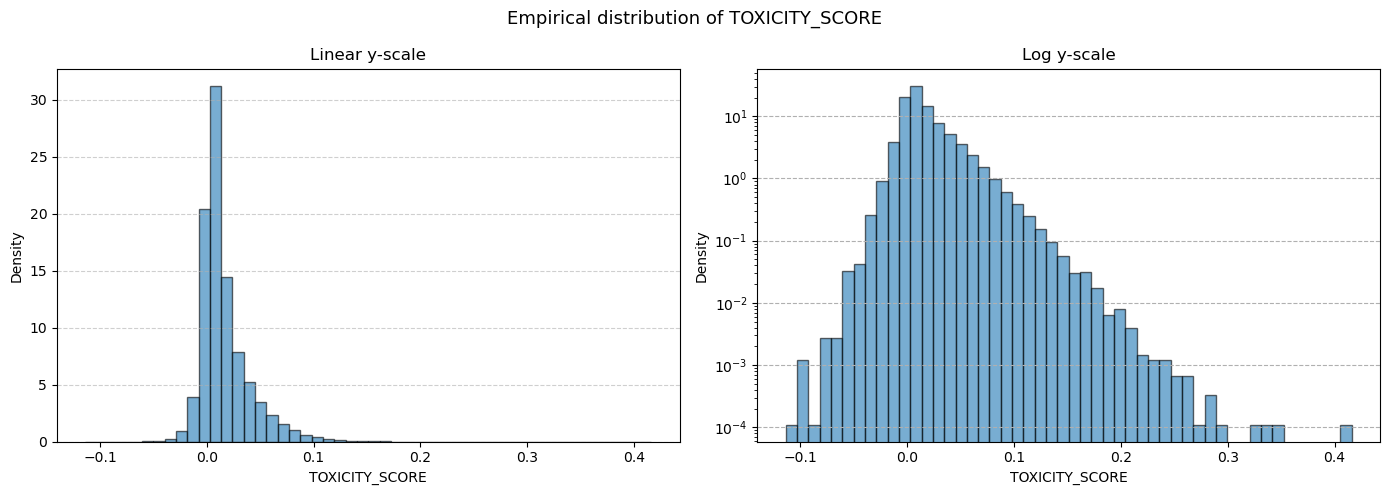

In [18]:
plot_empirical_distribution(interactions_df["TOXICITY_SCORE"], "TOXICITY_SCORE")

We now have a reliable, continuous measure of toxicity. But it's not necessarily easy to interpret it directly... We would like to accompany this continuous metric with a binary classification: "Is this toxicity score high? In other words, is this message toxic?"

Our approach is to define a new categroical metric `TOXICITY_CAT`, taking values 0 (not toxic) or 1 (maximally toxic).

For now, the threshod above which messages are flaggde as toxic is the quantile-75 of thetoxicity scores distribution. That is, we mark as significantly toxic the top 25% messages with highest score. While this is a reasonable and consistent approach, this threshold can be better set in the future and we will probably explore better ways to classify messages.

In [19]:
toxicity_bascule = interactions_df["TOXICITY_SCORE"].quantile(0.75)
print("75% quantile threshold:", toxicity_bascule)

interactions_df["TOXICITY_CAT"] = (interactions_df["TOXICITY_SCORE"] >= toxicity_bascule).astype(int)

75% quantile threshold: 0.02368686868687879


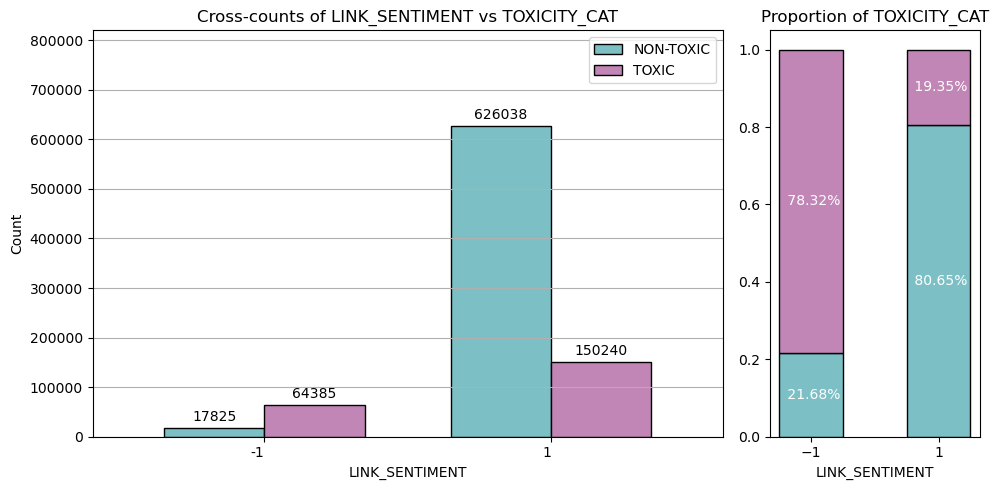

In [20]:
cross_count_SENTIMENT_TOXICITY(interactions_df)

At first, it appears that the majority of toxic messages are actualy labeled positive, which is not desirable as we explicited that, in our context, toxicity only comes with negativity. 

However, loking at the **proportions** of toxicity in each sentiment class (right barplot), we see that around 78% of negative messages are labeled toxic, while only 19% of positive messages were. Therefore, we can confidently state that neative messages are muvh more likely to be toxic (which makes sense based on the properties we retained to define toxicity).

In the next cell, we enforce the rule that only messages with negative sentiment (`LINK_SENTIMENT` = −1) can be classified as toxic (`TOXICITY_CAT` = 1). This decision is based on a conceptual definition of toxicity as hostile, harmful, or abusive discourse, which fundamentally requires a negative emotional valence. Although positive/neutral-sentiment messages may sometimes contain high levels of features like swearing or anger, classifying them as toxic would introduce significant false positives that do not align with the standard understanding of online harassment or abuse.

**Remark**

The continuous `TOXICITY_SCORE` is preserved even for the links that are ultimately filtered out by the sentiment check. This score serves as a crucial linguistic feature intensity metric, quantifying the sheer presence of aggressive or low-quality language features (e.g., swearing, anger, simplicity) independent of the link's overall "true" sentiment. By keeping the raw score, we retain valuable information for later analysis, such as comparing the distribution of strong language features across both toxic (negative sentiment) and non-toxic (positive sentiment) messages, which can reveal linguistic patterns related to intense discourse beyond just negative intent.

In [21]:
interactions_df["TOXICITY_CAT"] = ((interactions_df["TOXICITY_CAT"] == 1) & (interactions_df["LINK_SENTIMENT"] == -1)).astype(int)

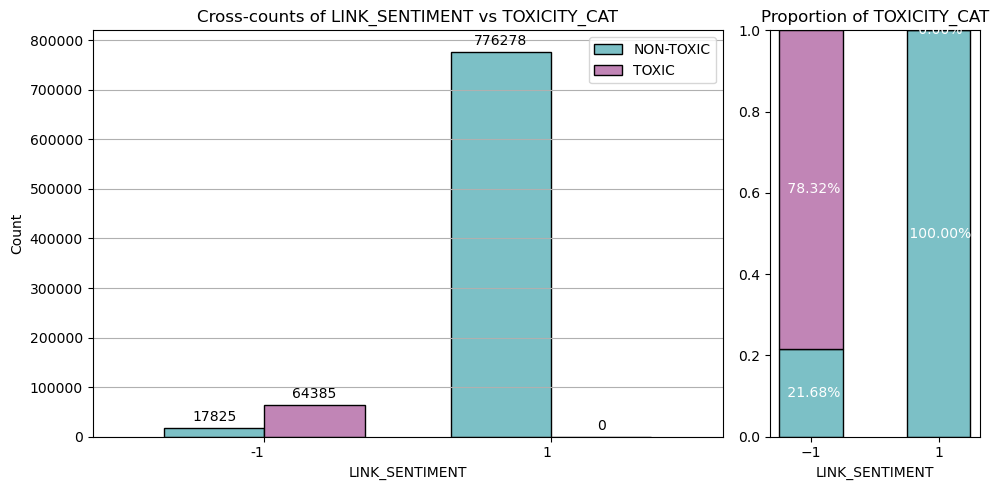

In [22]:
# Sanity check (to be removed in final version)
cross_count_SENTIMENT_TOXICITY(interactions_df)

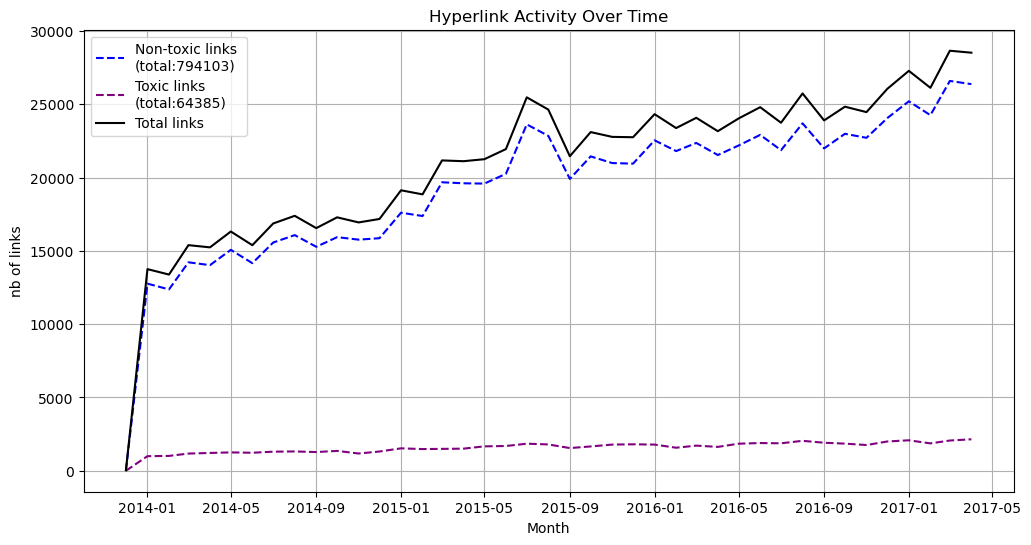

In [23]:
interactions_df["year_month"] = interactions_df["TIMESTAMP"].dt.to_period("M").dt.to_timestamp()

# Count interactions per month and sentiment
links_over_time_sent = (
    interactions_df.groupby(["year_month", "TOXICITY_CAT"])
    .size()
    .reset_index(name="n_links")
)

links_over_time_pivot = links_over_time_sent.pivot(
    index="year_month", columns="TOXICITY_CAT", values="n_links"
).fillna(0)

links_over_time_pivot["total"] = links_over_time_pivot.sum(axis=1)

toxicity_counts = interactions_df["TOXICITY_CAT"].value_counts()

plt.figure(figsize=(12, 6))
plt.plot(links_over_time_pivot.index, links_over_time_pivot[0], label=f"Non-toxic links \n(total:{toxicity_counts[0]})", color='blue', linestyle = '--')
plt.plot(links_over_time_pivot.index, links_over_time_pivot[1], label=f"Toxic links \n(total:{toxicity_counts[1]})", color='purple', linestyle = '--')
plt.plot(links_over_time_pivot.index, links_over_time_pivot["total"], label="Total links", color="black")

plt.title("Hyperlink Activity Over Time")
plt.xlabel("Month")
plt.ylabel("nb of links")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# Toxicity rolling normalization
rolling_window = "365D"

interactions_df["TOXICITY_SCORE_ROLLZ"] = (
    (interactions_df["TOXICITY_SCORE"] -
     interactions_df.rolling(rolling_window, on="TIMESTAMP")["TOXICITY_SCORE"].mean())
    / interactions_df.rolling(rolling_window, on="TIMESTAMP")["TOXICITY_SCORE"].std()
)


**Count Metrics:**
Foundation for all rate-based calculations. Counts are computed within a specific scope (not the entire dataset):
- `toxic_count`: Number of messages (links) classified as toxic within the given scope. A message is toxic if `toxicity_intensity > toxicity_threshold` (threshold defined below).
- `non_toxic_count`: Number of messages classified as non-toxic (`toxicity_intensity ≤ toxicity_threshold`) within the scope.
- `total_count`: Total number of messages within the scope = `toxic_count + non_toxic_count`.


In [ ]:
# TO DO

**Rate-Based Metrics:**
To quantify frequency and ratios of toxic behavior:
- `toxicity_rate`: 
Proportion of toxic source messages in a time window, `toxic_count / (toxic_count + non_toxic_count)`. Range: 0–1.
- An **optional** metric derived from this one would be the `toxicity_odds = (toxic_count / non_toxic_count) = toxicity_rate / (1 − toxicity_rate)` as it could be used to model odds and log-odds for logistic models in the following steps of the project.


In [ ]:
# TO DO

**Advanced Linguistic Metrics:**

These metrics could be useful and interesting when analysing the propagation of the negativity among subreddits. 
- `emotional_volatility`: Standard deviation of `toxicity_intensity`
- `personal_attack_indicators`: LIWC_You + LIWC_Negemo combinations
- `rational_discourse_score`: LIWC_CogMech + LIWC_Cause : this captures logical reasoning in comments since LIWC_CogMech relates to cognitive mechanisms and LIWC_Cause relates to causal reasoning (e.g., for both: LIWC_CogMech words include "cause", "know", "ought", while LIWC_Cause words include "because", "effect", "hence"). 
- `complexity_metrics`: Readability + word length + vocabulary richness.

In [ ]:
# To see if we end up keeping these metrics or not
# TO DO


**Directional Metrics:**
- `toxicity_out`: Toxic links sent by a subreddit (aggressor behavior)
- `toxicity_in`: Toxic links received by a subreddit (victim/target behavior)
- `toxicity_balance`: Net toxicity = `toxicity_out - toxicity_in`
- `reciprocal_toxicity`: Bidirectional toxic relationships between subreddit pairs which corresponds to the number of bidirectional edges in the toxic interaction graph.

In [ ]:
# Maybe Nathan since he is doing the graphs
# TO DO



**Temporal Metrics:**
- `toxicity_velocity`: Rate of change in toxicity over time (Δtoxicity_rate / Δtime)
- `toxicity_acceleration`: Second derivative (change in velocity)
- `toxicity_persistence`: Duration of sustained toxic behavior (consecutive toxic periods)

In [ ]:
# TO DO

# TO SEE IF WE END UP CHANGING HOW WE DEFINE THESE METRICS OR NOT

**Threshold Definitions:**
- `toxicity_threshold`: Threshold for classifying individual messages as toxic = `base_toxicity_offset + k×toxicity_std`, where k is a sensitivity parameter (k=1, capturing ~16% most toxic messages; alternative: k=0 for above-mean, or k=2 for top ~2.5%).
- `toxic_onset`: First occurrence of toxic behavior (based on first toxicity_intensity score above toxicity_threshold)
- `chronic_toxicity`: Sustained toxicity_rate > 50% for X+ consecutive weeks/ consecutive links
- `outbreak_threshold`: toxicity_rate > (platform_mean + 2×platform_std)
- `recovery_threshold`: A subreddit is considered recovered after a toxic period when the weekly toxicity_rate falls below 10% for X consecutive weeks. 

In [ ]:
# TO DO

### STEP 3: Network Construction

1. Build temporal network snapshots (monthly/yearly windows as shorter windows seem unreasonable given the data)  
2. Build directed graphs for each time period
3. Compute node edge attributes: degrees, toxicity metrics, network centrality measures, eigenvector centrality
4. Store as adjacency lists or graph objects for analysis


In [ ]:
# A priori Nathan to do but maybe to repslit
# TO DO


---
### **PHASE 2: OUTBREAK ANALYSIS** (Started but to finish after P2)

### Step 4: Find Communities
- Detect subreddit clusters (who interacts with whom?)
- Characterize each community's baseline behavior
- Track community changes over time

In [ ]:
# Could be nice to start analyse this 
# TO DO


### Step 5: Identify "Patient Zero"
- **Detect outbreaks**: When toxicity suddenly spikes
- **Find origins**: Which subreddit started it?
- **Measure impact**: How big did the outbreak get?


In [ ]:
# Could be nice to start analyse this 
# TO DO

---
### **PHASE 3: PROPAGATION ANALYSIS** (After P2)

### Step 6: Trace Cascades
- **Find chains**: A→B→C toxic spreading patterns
- **Analyze mutations**: How toxicity changes as it spreads
- **Model contagion**: What makes toxicity spread?

### Step 7: Study Immunity
- **Positive alliances**: Do friendly connections protect communities?
- **Resistance factors**: What makes communities immune?


---

### **PHASE 4: LIFE CYCLES & EVOLUTION** (After P2)

### Step 8: Find Cycles & Events
- **Periodicity**: Does toxicity follow seasonal patterns? (Fourier analysis)
- **Event correlation**: Do real-world events trigger spikes?

### Step 9: Track Evolution
- **Classify trajectories**: How do toxic communities evolve?: Is there a gradual radicalization? Or sudden outbreaks? Do we observe chronic toxicity?
- **Early warning**: Try to predict which communities will become toxic

---
### **PHASE 5: CONCLUSION & RESULT VALIDATION** (After P2)

### Step 10: Create Visualizations
We could create various visualizations to effectively communicate our findings. Examples such as :  Animated networks showing toxicity spread, Epidemic curves (like flu charts), etc.
